# Assignment 11

For the homework, use the **UCI Human Activity Recognition Using Smartphones**
dataset. Each observation is a 2.56-second window recorded from one person
wearing a waist-mounted smartphone. The two modalities are:

- accelerometer-derived features (`Acc` in the feature name);
- gyroscope-derived features (`Gyro` in the feature name).

The target is one of six activities. The `subject` identifier is essential:
measurements from one person must not be split between training and testing.
The goal is to compare what each modality contributes and how different fusion
strategies use that information.

## Required comparison

Build and compare these five systems:

1. accelerometer-only model;
2. gyroscope-only model;
3. early fusion: concatenate both feature blocks before modeling;
4. late fusion: train one model per modality and combine validation/test
   probabilities;
5. joint latent fusion: encode each modality separately, concatenate the two
   latent vectors, and predict from the shared representation.

Report accuracy, macro-F1, balanced accuracy, and a confusion matrix for every
system. Use the validation set to choose hyperparameters and the late-fusion
weight. Use the test set only for the final comparison.

In [1]:
from pathlib import Path
from types import SimpleNamespace
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# xgboost must be imported before torch: both ship their own libomp on macOS,
# and the other order segfaults on the first XGBoost fit.
try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBClassifier = None
    XGBOOST_AVAILABLE = False

import torch
import urllib.request
import zipfile
from torchview import draw_graph
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score, f1_score
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import SVC

try:
    import optuna
    OPTUNA_AVAILABLE = True
except ImportError:
    optuna = None
    OPTUNA_AVAILABLE = False

try:
    from imblearn.over_sampling import RandomOverSampler, SMOTE
    from imblearn.pipeline import Pipeline as ImbPipeline
    IMBLEARN_AVAILABLE = True
except ImportError:
    RandomOverSampler = None
    SMOTE = None
    ImbPipeline = None
    IMBLEARN_AVAILABLE = False

RANDOM_STATE = 42
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

torch.manual_seed(RANDOM_STATE)
# Keep torch's CPU thread pool from clashing with XGBoost's after the MLP trains.
torch.set_num_threads(1)

print(f"Device: {DEVICE}")

Device: mps


In [2]:
UCI_HAR_URL = (
    "https://archive.ics.uci.edu/static/public/240/"
    "human%2Bactivity%2Brecognition%2Busing%2Bsmartphones.zip"
)
UCI_HAR_DIR = Path("uci_har_data")
UCI_HAR_ROOT = UCI_HAR_DIR / "UCI HAR Dataset"
UCI_HAR_ARCHIVE = UCI_HAR_DIR / "uci_har.zip"

if not UCI_HAR_ROOT.exists():
    UCI_HAR_DIR.mkdir(parents=True, exist_ok=True)
    if not UCI_HAR_ARCHIVE.exists():
        print("Downloading the 58 MB UCI HAR archive...")
        urllib.request.urlretrieve(UCI_HAR_URL, UCI_HAR_ARCHIVE)
    with zipfile.ZipFile(UCI_HAR_ARCHIVE) as outer_archive:
        nested_name = "UCI HAR Dataset.zip"
        outer_archive.extract(nested_name, UCI_HAR_DIR)
    with zipfile.ZipFile(UCI_HAR_DIR / nested_name) as dataset_archive:
        dataset_archive.extractall(UCI_HAR_DIR)

feature_table = pd.read_csv(
    UCI_HAR_ROOT / "features.txt",
    sep=r"\s+",
    header=None,
    names=["feature_id", "feature_name"],
    engine="python",
)

def make_unique_names(names):
    counts = {}
    unique_names = []
    for name in names:
        count = counts.get(name, 0)
        unique_names.append(name if count == 0 else f"{name}__{count}")
        counts[name] = count + 1
    return unique_names

feature_names = make_unique_names(feature_table["feature_name"].tolist())

X_train_har = pd.read_csv(
    UCI_HAR_ROOT / "train" / "X_train.txt",
    sep=r"\s+", header=None, names=feature_names, engine="python",
)

X_test_har = pd.read_csv(
    UCI_HAR_ROOT / "test" / "X_test.txt",
    sep=r"\s+", header=None, names=feature_names, engine="python",
)

y_train_codes = pd.read_csv(
    UCI_HAR_ROOT / "train" / "y_train.txt",
    header=None, names=["activity_code"],
).squeeze()

y_test_codes = pd.read_csv(
    UCI_HAR_ROOT / "test" / "y_test.txt",
    header=None, names=["activity_code"],
).squeeze()

subject_train = pd.read_csv(
    UCI_HAR_ROOT / "train" / "subject_train.txt",
    header=None, names=["subject"],
).squeeze()

subject_test = pd.read_csv(
    UCI_HAR_ROOT / "test" / "subject_test.txt",
    header=None, names=["subject"],
).squeeze()

activity_labels = pd.read_csv(
    UCI_HAR_ROOT / "activity_labels.txt",
    sep=r"\s+", header=None, names=["activity_code", "activity"],
)

activity_map = dict(
    zip(activity_labels["activity_code"], activity_labels["activity"])
)

X_har = pd.concat([X_train_har, X_test_har], ignore_index=True)
y_har = pd.concat([y_train_codes, y_test_codes], ignore_index=True).map(activity_map)
subject_har = pd.concat([subject_train, subject_test], ignore_index=True).to_numpy()

print("Feature table:", X_har.shape)
print("Target classes:", sorted(y_har.unique()))
print("Subjects:", len(np.unique(subject_har)))
display(X_har.head())
display(y_har.value_counts().rename("windows").to_frame())

Feature table: (10299, 561)
Target classes: ['LAYING', 'SITTING', 'STANDING', 'WALKING', 'WALKING_DOWNSTAIRS', 'WALKING_UPSTAIRS']
Subjects: 30


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.074323,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,0.158075,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,0.414503,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,0.404573,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,0.087753,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892


,windows
activity_code,
LAYING,1944
STANDING,1906
SITTING,1777
WALKING,1722
WALKING_UPSTAIRS,1544
WALKING_DOWNSTAIRS,1406


In [3]:
accelerometer_columns = [column for column in X_har.columns if "Acc" in str(column)]
gyroscope_columns = [column for column in X_har.columns if "Gyro" in str(column)]

assert accelerometer_columns, "No accelerometer columns were detected."
assert gyroscope_columns, "No gyroscope columns were detected."

X_acc_har = X_har[accelerometer_columns].astype("float32")
X_gyro_har = X_har[gyroscope_columns].astype("float32")
X_early_har = pd.concat([X_acc_har, X_gyro_har], axis=1)

label_encoder_har = LabelEncoder().fit(y_har)
y_har_encoded = label_encoder_har.transform(y_har)

print("Accelerometer features:", X_acc_har.shape[1])
print("Gyroscope features:", X_gyro_har.shape[1])
print("Early-fusion features:", X_early_har.shape[1])

Accelerometer features: 345
Gyroscope features: 213
Early-fusion features: 558


In [4]:
outer_splitter = StratifiedGroupKFold(
  n_splits=5, shuffle=True, random_state=RANDOM_STATE
)

train_val_relative, test_relative = next(outer_splitter.split(X_har, y_har_encoded, groups=subject_har))

train_val_indices = np.asarray(train_val_relative)
test_indices = np.asarray(test_relative)

inner_splitter = StratifiedGroupKFold(
  n_splits=4, shuffle=True, random_state=RANDOM_STATE
)

train_relative, val_relative = next(
  inner_splitter.split(
    X_har.iloc[train_val_indices],
    y_har_encoded[train_val_indices],
    groups=subject_har[train_val_indices],
  )
)

train_indices = train_val_indices[train_relative]
val_indices = train_val_indices[val_relative]

def subjects_in(indices):
  return set(subject_har[indices])

print("Rows:", {
  "train": len(train_indices),
  "validation": len(val_indices),
  "test": len(test_indices),
})

print("Subjects:", {
  "train": len(subjects_in(train_indices)),
  "validation": len(subjects_in(val_indices)),
  "test": len(subjects_in(test_indices)),
})

assert subjects_in(train_indices).isdisjoint(subjects_in(val_indices))
assert subjects_in(train_indices).isdisjoint(subjects_in(test_indices))
assert subjects_in(val_indices).isdisjoint(subjects_in(test_indices))

Rows: {'train': 6193, 'validation': 2144, 'test': 1962}
Subjects: {'train': 18, 'validation': 6, 'test': 6}


In [5]:
# Ready-to-use modality blocks for the five homework experiments.
har_blocks = {
  "accelerometer": X_acc_har,
  "gyroscope": X_gyro_har,
  "early_fusion": X_early_har,
}

har_splits = {
  "train": train_indices,
  "validation": val_indices,
  "test": test_indices,
}

for name, block in har_blocks.items():
  print(name, block.shape)

accelerometer (10299, 345)
gyroscope (10299, 213)
early_fusion (10299, 558)


## Single modality baselines

In [6]:
y_train_har = y_har_encoded[train_indices]
y_test_har = y_har_encoded[test_indices]

def plot_confusion(name, method, y_true, prediction):
  _, ax = plt.subplots(figsize=(7, 6))
  ConfusionMatrixDisplay.from_predictions(
    y_true, prediction,
    display_labels=label_encoder_har.classes_,
    normalize="true",
    values_format=".2f",
    xticks_rotation=45,
    cmap="Blues",
    colorbar=False,
    ax=ax,
  )
  ax.set_title(f"{method}: {name}")
  plt.show()

def report_model(name, model, method, X_fit, y_fit, X_eval, y_eval):
  model.fit(X_fit, y_fit)
  prediction = model.predict(X_eval)
  plot_confusion(name, method, y_eval, prediction)
  return {
    "model": name,
    "method": method,
    "accuracy": accuracy_score(y_eval, prediction),
    "macro_f1": f1_score(y_eval, prediction, average="macro"),
    "balanced_accuracy": balanced_accuracy_score(y_eval, prediction),
  }

def make_logreg():
  model = LogisticRegression(
    max_iter=1500,
    class_weight="balanced"
  )

  return model

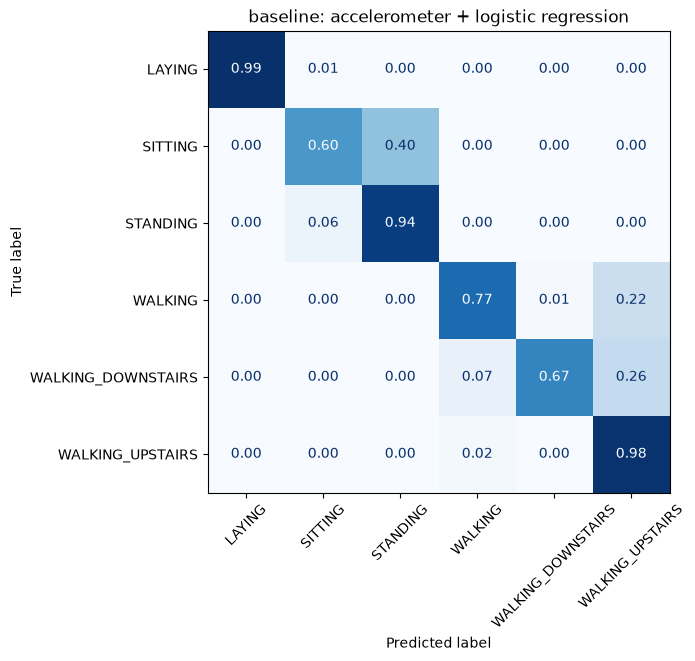

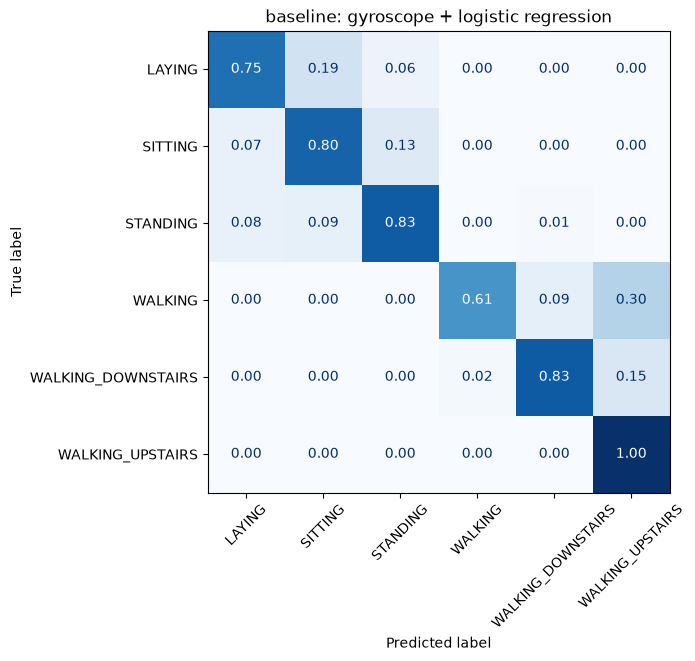

,model,method,accuracy,macro_f1,balanced_accuracy
0,accelerometer + logistic regression,baseline,0.830785,0.825016,0.824798
1,gyroscope + logistic regression,baseline,0.797146,0.797216,0.801956


In [7]:
results = []
for name in ["accelerometer", "gyroscope"]:
  X_block = har_blocks[name]
  results.append(report_model(
    f"{name} + logistic regression", make_logreg(), "baseline",
    X_block.iloc[train_indices], y_train_har,
    X_block.iloc[test_indices], y_test_har,
  ))

display(pd.DataFrame(results))

## Early fusion

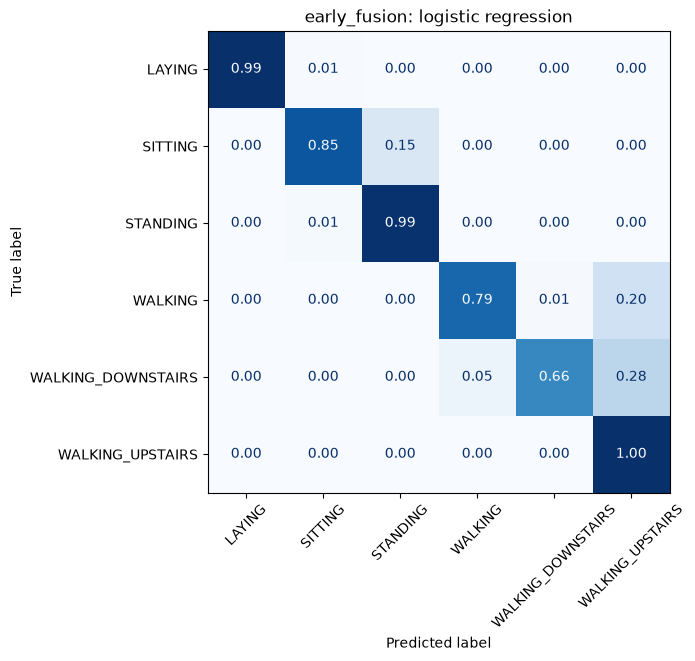

,model,method,accuracy,macro_f1,balanced_accuracy
0,accelerometer + logistic regression,baseline,0.830785,0.825016,0.824798
1,gyroscope + logistic regression,baseline,0.797146,0.797216,0.801956
2,logistic regression,early_fusion,0.890418,0.882010,0.880200


In [8]:
X_block = har_blocks["early_fusion"]

results.append(report_model(
  "logistic regression", make_logreg(), "early_fusion",
  X_block.iloc[train_indices], y_train_har,
  X_block.iloc[test_indices], y_test_har,
))

display(pd.DataFrame(results))

# Late fusion

,model,method,accuracy,macro_f1,balanced_accuracy
0,accelerometer + logistic regression,baseline,0.830785,0.825016,0.824798
1,gyroscope + logistic regression,baseline,0.797146,0.797216,0.801956
2,logistic regression,early_fusion,0.890418,0.882010,0.880200
3,logistic regression (alpha=0.5),late_fusion,0.889399,0.886484,0.885083


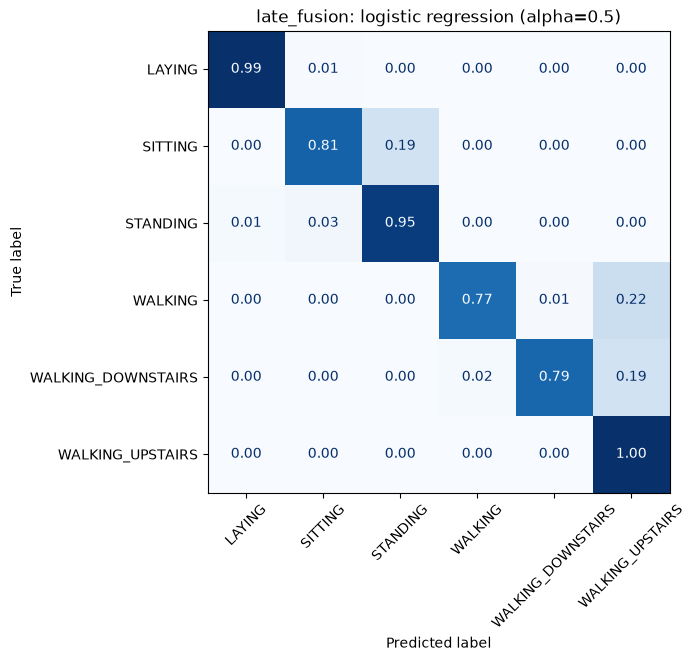

In [9]:
y_val_har = y_har_encoded[val_indices]

X_acc = har_blocks["accelerometer"]
X_gyro = har_blocks["gyroscope"]

acc_model = make_logreg().fit(X_acc.iloc[train_indices], y_train_har)
gyro_model = make_logreg().fit(X_gyro.iloc[train_indices], y_train_har)

acc_val_proba = acc_model.predict_proba(X_acc.iloc[val_indices])
gyro_val_proba = gyro_model.predict_proba(X_gyro.iloc[val_indices])

weights = np.linspace(0, 1, 11)
validation_scores = []
for alpha in weights:
  val_prediction = np.argmax(alpha * acc_val_proba + (1 - alpha) * gyro_val_proba, axis=1)
  validation_scores.append(f1_score(y_val_har, val_prediction, average="macro"))

alpha = weights[np.argmax(validation_scores)]

acc_test_proba = acc_model.predict_proba(X_acc.iloc[test_indices])
gyro_test_proba = gyro_model.predict_proba(X_gyro.iloc[test_indices])
prediction = np.argmax(alpha * acc_test_proba + (1 - alpha) * gyro_test_proba, axis=1)

results.append({
  "model": f"logistic regression (alpha={alpha:.1f})",
  "method": "late_fusion",
  "accuracy": accuracy_score(y_test_har, prediction),
  "macro_f1": f1_score(y_test_har, prediction, average="macro"),
  "balanced_accuracy": balanced_accuracy_score(y_test_har, prediction),
})

display(pd.DataFrame(results))
plot_confusion(results[-1]["model"], "late_fusion", y_test_har, prediction)

## Joint fusion

In [10]:
class JointFusionMLP(nn.Module):
  def __init__(self, n_acc, n_gyro, n_classes):
    super().__init__()
    self.acc_encoder = nn.Sequential(
      nn.Linear(n_acc, 64),
      nn.ReLU(),
      nn.Linear(64, 16)
    )

    self.gyro_encoder = nn.Sequential(
      nn.Linear(n_gyro, 64),
      nn.ReLU(),
      nn.Linear(64, 16)
    )

    self.head = nn.Sequential(
      nn.ReLU(),
      nn.Linear(32, n_classes)
    )

  def encode(self, acc, gyro):
    z_acc = self.acc_encoder(acc)
    z_gyro = self.gyro_encoder(gyro)
    return torch.cat([z_acc, z_gyro], dim=1)

  def forward(self, acc, gyro, return_latent=False):
    latent = self.encode(acc, gyro)
    logits = self.head(latent)
    return (logits, latent) if return_latent else logits

def to_tensor(X_block, indices):
  return torch.tensor(X_block.iloc[indices].to_numpy(), dtype=torch.float32).to(DEVICE)

In [11]:
Xa_train = to_tensor(X_acc, train_indices)
Xg_train = to_tensor(X_gyro, train_indices)

Xa_val = to_tensor(X_acc, val_indices)
Xg_val = to_tensor(X_gyro, val_indices)

Xa_test = to_tensor(X_acc, test_indices)
Xg_test = to_tensor(X_gyro, test_indices)

Validation macro-F1: 0.965728586003728


,model,method,accuracy,macro_f1,balanced_accuracy
0,accelerometer + logistic regression,baseline,0.830785,0.825016,0.824798
1,gyroscope + logistic regression,baseline,0.797146,0.797216,0.801956
2,logistic regression,early_fusion,0.890418,0.882010,0.880200
3,logistic regression (alpha=0.5),late_fusion,0.889399,0.886484,0.885083
4,Multi-layer Pes Patron,joint_fusion,0.867992,0.861253,0.859170


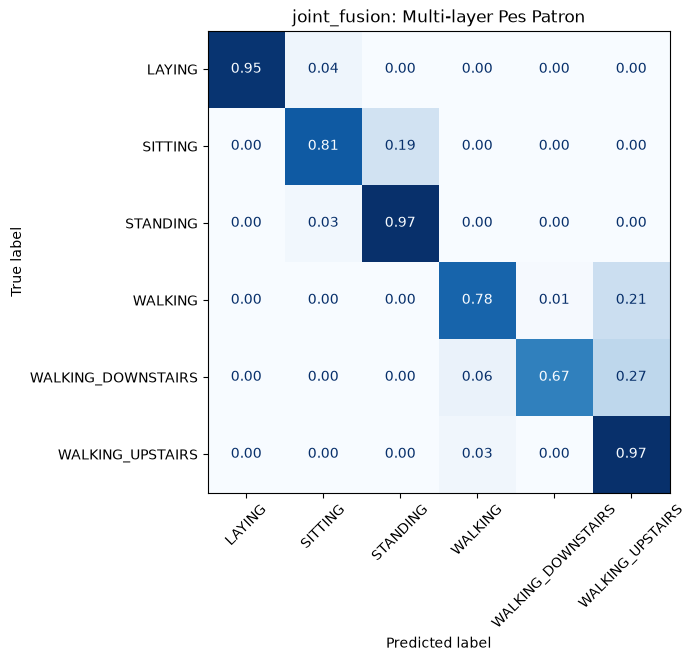

In [12]:
N_EPOCH = 25

fusion_model = JointFusionMLP(
  X_acc.shape[1],
  X_gyro.shape[1],
  len(label_encoder_har.classes_)
).to(DEVICE)

optimizer = torch.optim.Adam(
  fusion_model.parameters(),
  lr=1e-3,
  weight_decay=1e-4,
)

loss_fn = nn.CrossEntropyLoss()

train_dataset = TensorDataset(
  Xa_train,
  Xg_train,
  torch.tensor(y_train_har).to(DEVICE),
)

train_loader = DataLoader(train_dataset,  batch_size=64, shuffle=True)

for epoch in range(N_EPOCH):
  fusion_model.train()

  for acc_batch, gyro_batch, target_batch in train_loader:
    optimizer.zero_grad()
    loss = loss_fn(fusion_model(acc_batch, gyro_batch), target_batch)
    loss.backward()
    optimizer.step()

fusion_model.eval()
with torch.no_grad():
  val_prediction = fusion_model(Xa_val, Xg_val).argmax(1).cpu().numpy()
  test_logits, test_latent = fusion_model(Xa_test, Xg_test, return_latent=True)

print("Validation macro-F1:", f1_score(y_val_har, val_prediction, average="macro"))

prediction = test_logits.argmax(1).cpu().numpy()
results.append({
  "model": "Multi-layer Pes Patron",
  "method": "joint_fusion",
  "accuracy": accuracy_score(y_test_har, prediction),
  "macro_f1": f1_score(y_test_har, prediction, average="macro"),
  "balanced_accuracy": balanced_accuracy_score(y_test_har, prediction),
})

display(pd.DataFrame(results))
plot_confusion(results[-1]["model"], "joint_fusion", y_test_har, prediction)

# XGBoost

In [13]:
N_TRIALS = 50

def make_xgboost(**params):
  model = XGBClassifier(
    objective="multi:softprob",
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=0,
    **params,
  )

  return model

def tune_xgboost(X_block, n_trials=N_TRIALS):
  def objective(trial):
    params = {
      "n_estimators": trial.suggest_int("n_estimators", 50, 800, step=50),
      "max_depth": trial.suggest_int("max_depth", 2, 12),
      "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.35, log=True),
      "min_child_weight": trial.suggest_float("min_child_weight", 1.0, 20.0, log=True),
      "subsample": trial.suggest_float("subsample", 0.25, 1.0),
      "colsample_bytree": trial.suggest_float("colsample_bytree", 0.20, 1.0),
      "gamma": trial.suggest_float("gamma", 0.0, 5.0),
      "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
      "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 30.0, log=True),
    }

    model = make_xgboost(**params).fit(X_block.iloc[train_indices], y_train_har)
    prediction = model.predict(X_block.iloc[val_indices])
    return f1_score(y_val_har, prediction, average="macro")

  optuna.logging.set_verbosity(optuna.logging.WARNING)
  study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
  )
  study.optimize(objective, n_trials=n_trials)

  return study.best_params

### XGBoost baselines

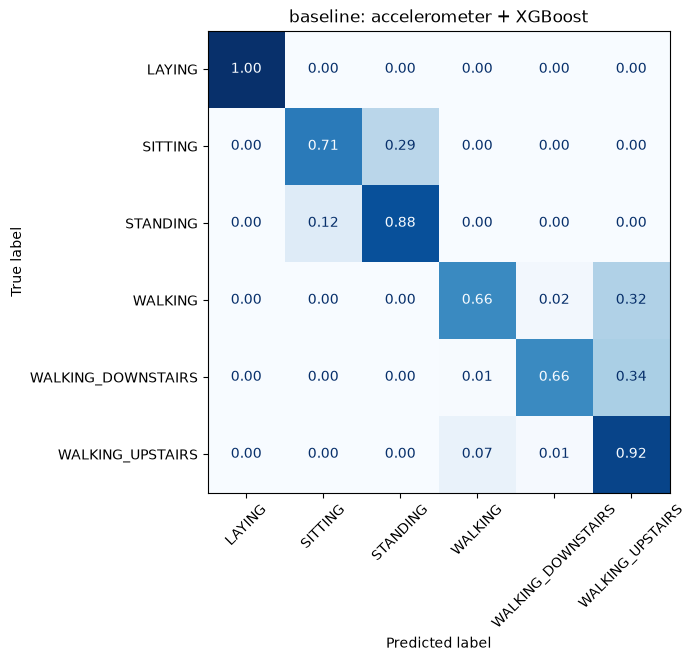

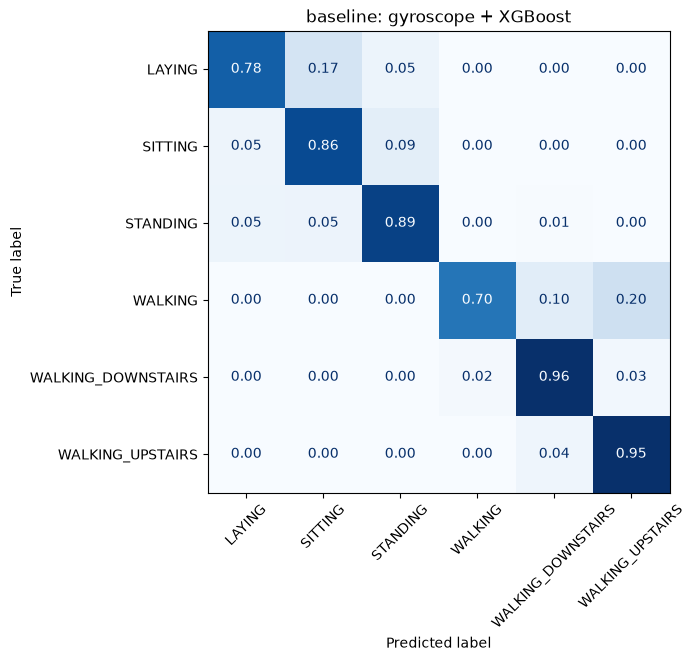

,model,method,accuracy,macro_f1,balanced_accuracy
0,accelerometer + logistic regression,baseline,0.830785,0.825016,0.824798
1,gyroscope + logistic regression,baseline,0.797146,0.797216,0.801956
2,logistic regression,early_fusion,0.890418,0.882010,0.880200
3,logistic regression (alpha=0.5),late_fusion,0.889399,0.886484,0.885083
4,Multi-layer Pes Patron,joint_fusion,0.867992,0.861253,0.859170
5,accelerometer + XGBoost,baseline,0.811417,0.805851,0.803286
6,gyroscope + XGBoost,baseline,0.851682,0.852129,0.857535


In [14]:
xgb_params = {}
for name in ["accelerometer", "gyroscope"]:
  X_block = har_blocks[name]
  xgb_params[name] = tune_xgboost(X_block)
  results.append(report_model(
    f"{name} + XGBoost", make_xgboost(**xgb_params[name]), "baseline",
    X_block.iloc[train_indices], y_train_har,
    X_block.iloc[test_indices], y_test_har,
  ))

display(pd.DataFrame(results))

### XGBoost early fusion

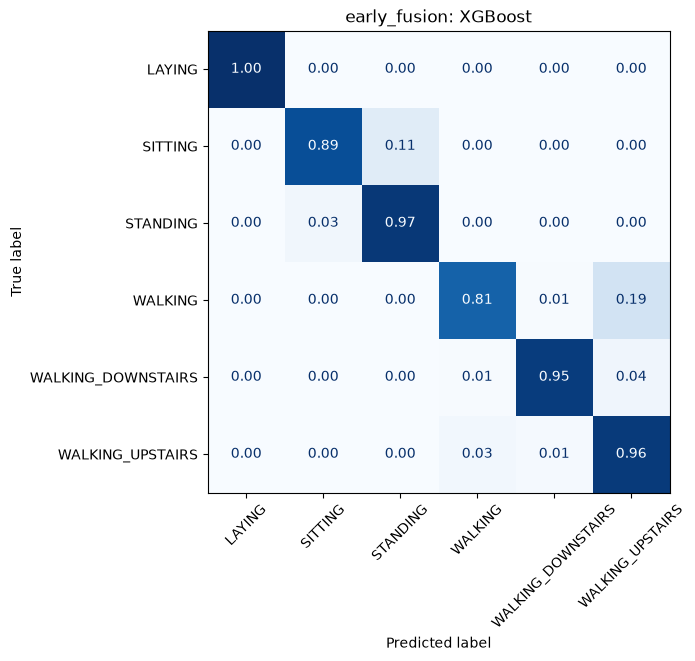

,model,method,accuracy,macro_f1,balanced_accuracy
0,accelerometer + logistic regression,baseline,0.830785,0.825016,0.824798
1,gyroscope + logistic regression,baseline,0.797146,0.797216,0.801956
2,logistic regression,early_fusion,0.890418,0.882010,0.880200
3,logistic regression (alpha=0.5),late_fusion,0.889399,0.886484,0.885083
4,Multi-layer Pes Patron,joint_fusion,0.867992,0.861253,0.859170
5,accelerometer + XGBoost,baseline,0.811417,0.805851,0.803286
6,gyroscope + XGBoost,baseline,0.851682,0.852129,0.857535
7,XGBoost,early_fusion,0.928644,0.927239,0.927780


In [15]:
X_block = har_blocks["early_fusion"]
xgb_params["early_fusion"] = tune_xgboost(X_block)

results.append(report_model(
  "XGBoost", make_xgboost(**xgb_params["early_fusion"]), "early_fusion",
  X_block.iloc[train_indices], y_train_har,
  X_block.iloc[test_indices], y_test_har,
))

display(pd.DataFrame(results))

### XGBoost late fusion

,model,method,accuracy,macro_f1,balanced_accuracy
0,accelerometer + logistic regression,baseline,0.830785,0.825016,0.824798
1,gyroscope + logistic regression,baseline,0.797146,0.797216,0.801956
2,logistic regression,early_fusion,0.890418,0.882010,0.880200
3,logistic regression (alpha=0.5),late_fusion,0.889399,0.886484,0.885083
4,Multi-layer Pes Patron,joint_fusion,0.867992,0.861253,0.859170
5,accelerometer + XGBoost,baseline,0.811417,0.805851,0.803286
6,gyroscope + XGBoost,baseline,0.851682,0.852129,0.857535
7,XGBoost,early_fusion,0.928644,0.927239,0.927780
8,XGBoost (alpha=0.5),late_fusion,0.927625,0.926410,0.928708


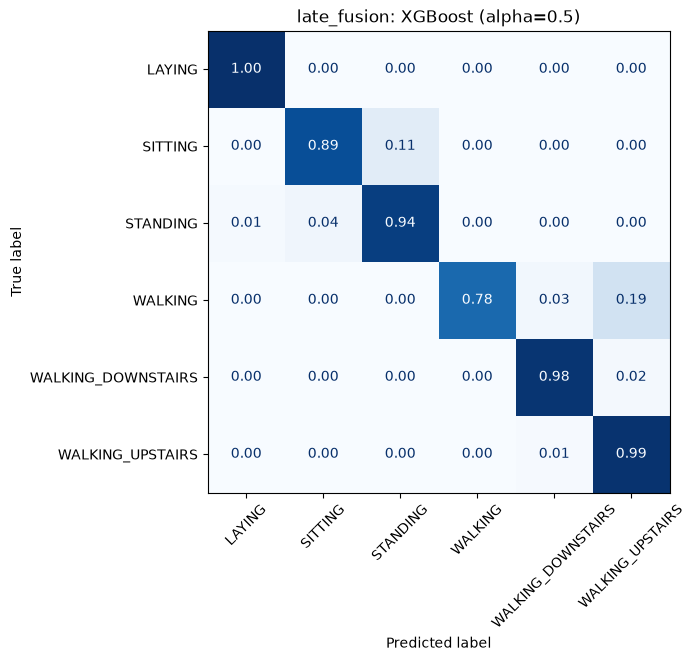

In [ ]:
acc_model = make_xgboost(**xgb_params["accelerometer"]).fit(X_acc.iloc[train_indices], y_train_har)

gyro_model = make_xgboost(**xgb_params["gyroscope"]).fit(X_gyro.iloc[train_indices], y_train_har)

acc_val_proba = acc_model.predict_proba(X_acc.iloc[val_indices])
gyro_val_proba = gyro_model.predict_proba(X_gyro.iloc[val_indices])

validation_scores = []
for alpha in weights:
  val_prediction = np.argmax(alpha * acc_val_proba + (1 - alpha) * gyro_val_proba, axis=1)
  validation_scores.append(f1_score(y_val_har, val_prediction, average="macro"))

alpha = weights[np.argmax(validation_scores)]

acc_test_proba = acc_model.predict_proba(X_acc.iloc[test_indices])
gyro_test_proba = gyro_model.predict_proba(X_gyro.iloc[test_indices])
prediction = np.argmax(alpha * acc_test_proba + (1 - alpha) * gyro_test_proba, axis=1)

results.append({
  "model": f"XGBoost (alpha={alpha:.1f})",
  "method": "late_fusion",
  "accuracy": accuracy_score(y_test_har, prediction),
  "macro_f1": f1_score(y_test_har, prediction, average="macro"),
  "balanced_accuracy": balanced_accuracy_score(y_test_har, prediction),
})

display(pd.DataFrame(results))
plot_confusion(results[-1]["model"], "late_fusion", y_test_har, prediction)

# Results

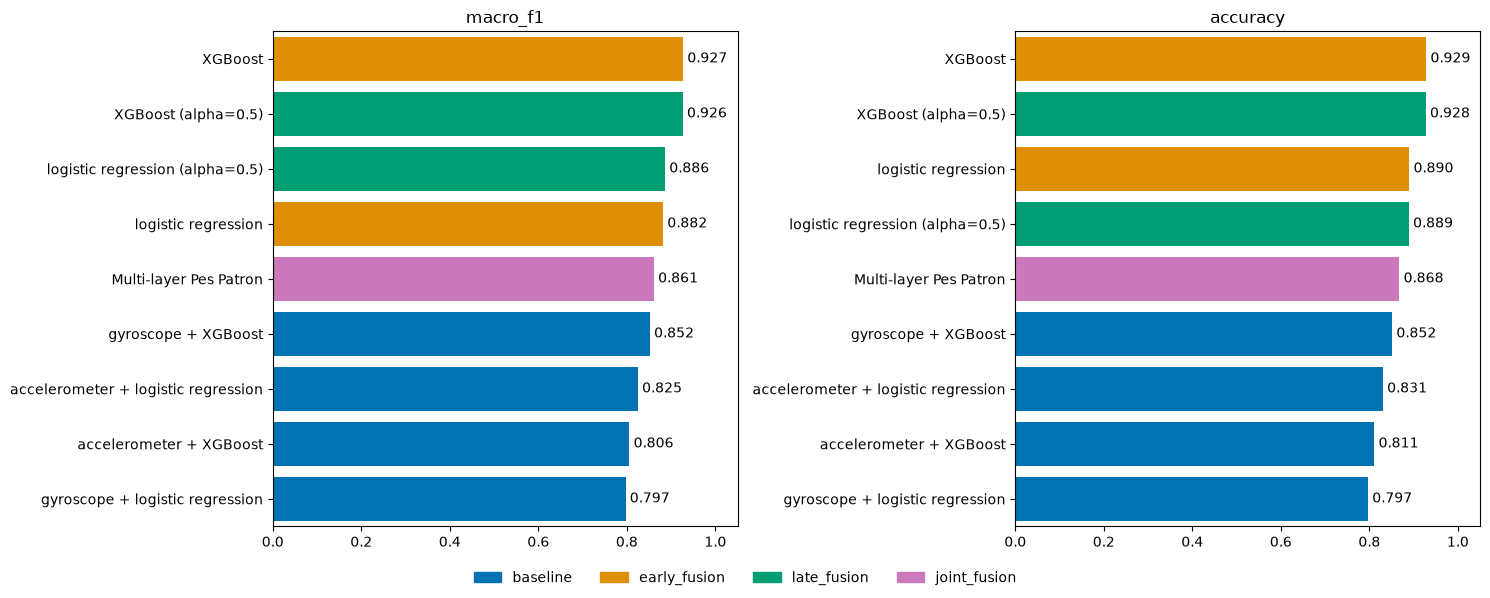

In [18]:
results_df = pd.DataFrame(results)

method_order = ["baseline", "early_fusion", "late_fusion", "joint_fusion"]
method_colors = dict(zip(method_order, ["#0173b2", "#de8f05", "#029e73", "#cc78bc"]))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, metric in zip(axes, ["macro_f1", "accuracy"]):
  sns.barplot(
    data=results_df.sort_values(metric, ascending=False),
    x=metric, y="model", hue="method",
    hue_order=method_order, palette=method_colors, saturation=1,
    dodge=False, legend=False, ax=ax,
  )

  for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

  ax.set(xlim=(0, 1.05), title=metric, xlabel="", ylabel="")

handles = [plt.Rectangle((0, 0), 1, 1, color=method_colors[method]) for method in method_order]
fig.legend(handles, method_order, loc="lower center", ncol=len(method_order), frameon=False)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

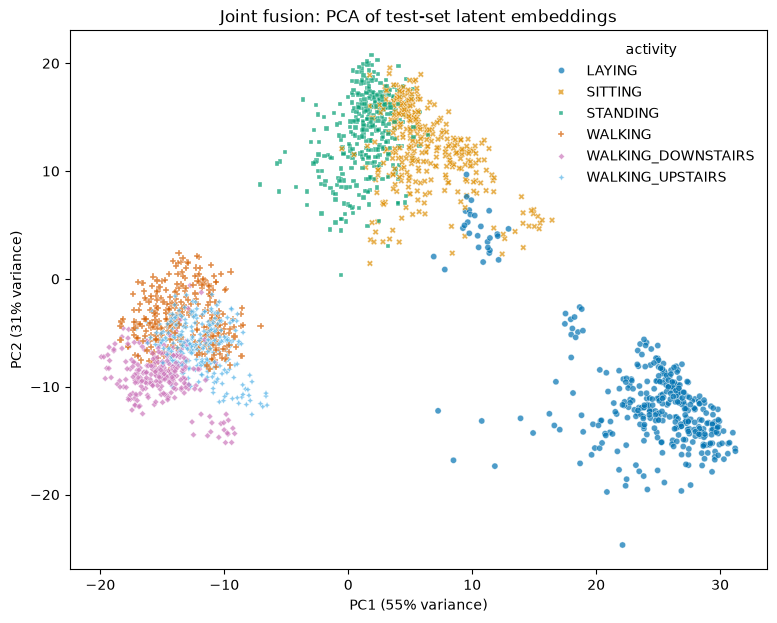

In [19]:
latent_pca = PCA(n_components=2, random_state=RANDOM_STATE)
latent_2d = latent_pca.fit_transform(test_latent.cpu().numpy())

latent_df = pd.DataFrame(latent_2d, columns=["PC1", "PC2"])
latent_df["activity"] = label_encoder_har.inverse_transform(y_test_har)

activity_order = label_encoder_har.classes_
activity_colors = dict(zip(activity_order, ["#0173b2", "#de8f05", "#029e73", "#d55e00", "#cc78bc", "#56b4e9"]))

fig, ax = plt.subplots(figsize=(9, 7))
sns.scatterplot(
  data=latent_df, x="PC1", y="PC2",
  hue="activity", style="activity",
  hue_order=activity_order, style_order=activity_order,
  palette=activity_colors, s=20, alpha=0.7, ax=ax,
)

pc1_var, pc2_var = latent_pca.explained_variance_ratio_
ax.set(
  title="Joint fusion: PCA of test-set latent embeddings",
  xlabel=f"PC1 ({pc1_var:.0%} variance)",
  ylabel=f"PC2 ({pc2_var:.0%} variance)",
)
ax.legend(title="activity", frameon=False)
plt.show()

# Conclusion

1. Do accelerometer and gyroscope achieve similar performance when modeled
   separately? Which activities are difficult for each modality? - Yes. Accelerometer confuses sitting and standing, gyroscope confuses sitting, standing and laying but less. Both modalities confuse walking (straight, up, down). This holds for XGBoost and LogReg.
2. Does early fusion improve macro-F1 over the best single-modality model? - Yes. Any fusion model is better than any baseline model.
3. Which validation-set probability weight gives the best late-fusion result? 0.5 (both in LogReg and XGBoost).
4. Does joint latent fusion outperform concatenation? Inspect the learned
   latent representation with PCA or UMAP. - No. As said previously, WALKING activities cluster together. LAYING is distinct enough from SITTING and STANDING (which together form another cluster) but some observations also cluster there.
5. Verify that the reported test improvement is not caused by subject leakage.
6. Discuss one situation in which late fusion would be preferable to early or
   latent fusion. - Missing data, noisy data. Good encoder can still output better embedding, than just plain early fusion model.